# DSCI 552 HW5

Justin Li

zyli@usc.edu

34004214

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor
pd.set_option("display.width", 140)

## 1(a)

In [2]:
ai = pd.read_csv("../data/acute_inflammations/diagnosis.data", sep="\t", encoding="utf-16", header=None, decimal=",")
ai.columns = ["temp", "nausea", "lumbar", "urine", "mict", "burn", "bladder", "nephritis"]
for c in ai.columns[1:]:
    ai[c] = (ai[c] == "yes").astype(int)
names = {(0, 0): "neither", (1, 0): "bladder only", (0, 1): "nephritis only", (1, 1): "both"}
X1 = ai.iloc[:, :6]
y1 = pd.Series([names[k] for k in zip(ai.bladder, ai.nephritis)], name="dx")
print(ai.shape)
print(f"Temperature range: {ai.temp.min()} to {ai.temp.max()}")
print(y1.value_counts().to_string())
ai.head()

(120, 8)
Temperature range: 35.5 to 41.5
dx
bladder only      40
nephritis only    31
neither           30
both              19


,temp,nausea,lumbar,urine,mict,burn,bladder,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


## 1(b)

Leaves: 6, depth: 4, training accuracy: 1.000


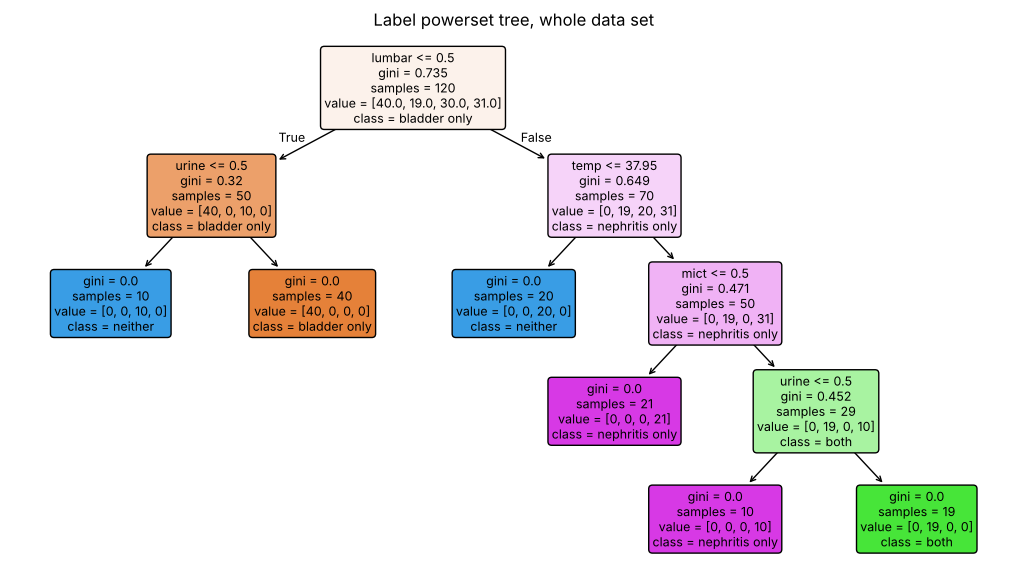

In [3]:
t1 = DecisionTreeClassifier(random_state=552).fit(X1, y1)
print(f"Leaves: {t1.get_n_leaves()}, depth: {t1.get_depth()}, training accuracy: {t1.score(X1, y1):.3f}")
plt.figure(figsize=(13, 7))
plot_tree(t1, feature_names=list(X1.columns), class_names=list(t1.classes_), filled=True, rounded=True, fontsize=9)
plt.title("Label powerset tree, whole data set")
plt.show()

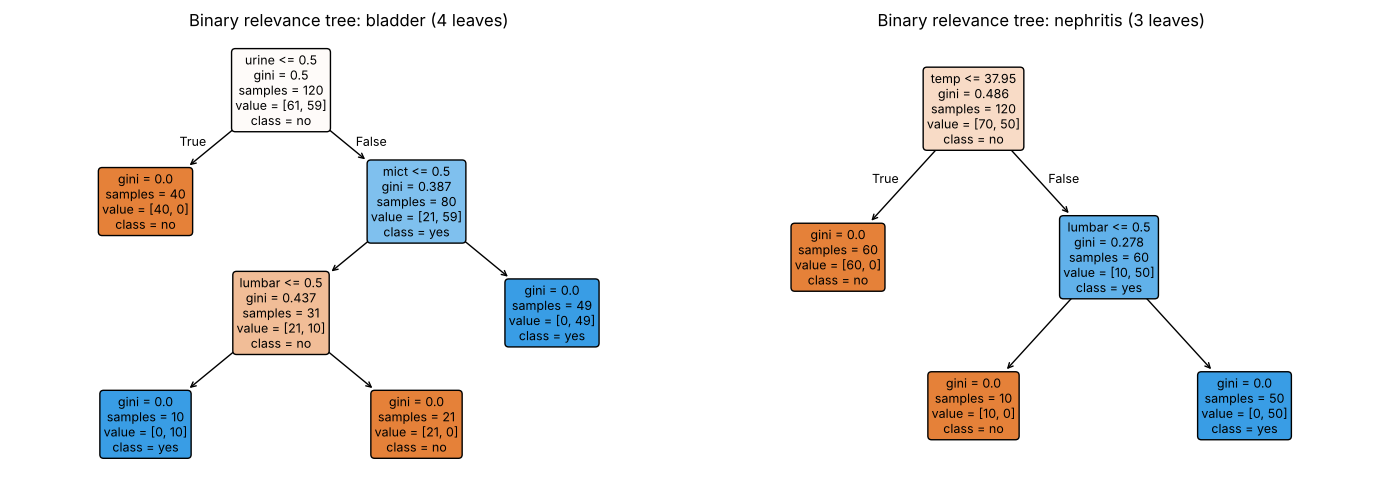

In [4]:
br = {k: DecisionTreeClassifier(random_state=552).fit(X1, ai[k]) for k in ["bladder", "nephritis"]}
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, (k, m) in zip(ax, br.items()):
    plot_tree(m, feature_names=list(X1.columns), class_names=["no", "yes"], filled=True, rounded=True, fontsize=9, ax=a)
    a.set_title(f"Binary relevance tree: {k} ({m.get_n_leaves()} leaves)")
plt.tight_layout()
plt.show()

## 1(c)

In [5]:
def rules(m, f, cn):
    t, out = m.tree_, []
    def go(n, c):
        if t.children_left[n] == -1:
            out.append(f"IF {' AND '.join(c) or 'TRUE'} THEN {cn[t.value[n][0].argmax()]} (n = {t.n_node_samples[n]})")
            return
        j, th = f[t.feature[n]], t.threshold[n]
        a, b = (f"temp <= {th:.2f}", f"temp > {th:.2f}") if j == "temp" else (f"{j} = no", f"{j} = yes")
        go(t.children_left[n], c + [a])
        go(t.children_right[n], c + [b])
    go(0, [])
    return out
print("\n".join(rules(t1, list(X1.columns), t1.classes_)))

IF lumbar = no AND urine = no THEN neither (n = 10)
IF lumbar = no AND urine = yes THEN bladder only (n = 40)
IF lumbar = yes AND temp <= 37.95 THEN neither (n = 20)
IF lumbar = yes AND temp > 37.95 AND mict = no THEN nephritis only (n = 21)
IF lumbar = yes AND temp > 37.95 AND mict = yes AND urine = no THEN nephritis only (n = 10)
IF lumbar = yes AND temp > 37.95 AND mict = yes AND urine = yes THEN both (n = 19)


In [6]:
for k, m in br.items():
    print(f"{k}:")
    print("\n".join(rules(m, list(X1.columns), ["no", "yes"])))
    print()

bladder:
IF urine = no THEN no (n = 40)
IF urine = yes AND mict = no AND lumbar = no THEN yes (n = 10)
IF urine = yes AND mict = no AND lumbar = yes THEN no (n = 21)
IF urine = yes AND mict = yes THEN yes (n = 49)

nephritis:
IF temp <= 37.95 THEN no (n = 60)
IF temp > 37.95 AND lumbar = no THEN no (n = 10)
IF temp > 37.95 AND lumbar = yes THEN yes (n = 50)



## 1(d)

In [7]:
cv1 = StratifiedKFold(5, shuffle=True, random_state=552)
pp = t1.cost_complexity_pruning_path(X1, y1)
rows = []
for a in pp.ccp_alphas:
    m = DecisionTreeClassifier(random_state=552, ccp_alpha=a).fit(X1, y1)
    s = cross_val_score(DecisionTreeClassifier(random_state=552, ccp_alpha=a), X1, y1, cv=cv1)
    rows.append({"alpha": a, "leaves": m.get_n_leaves(), "depth": m.get_depth(), "train_acc": m.score(X1, y1), "cv_acc": s.mean(), "cv_se": s.std() / np.sqrt(len(s))})
pt = pd.DataFrame(rows)
print(pt.round(4).to_string(index=False))
best = pt.cv_acc.max()
ab = pt[pt.cv_acc == best].alpha.max()
print(f"Chosen alpha: {ab:.4f}")

 alpha  leaves  depth  train_acc  cv_acc  cv_se
0.0000       6      4     1.0000  0.9917 0.0075
0.0982       4      2     0.8417  0.8583 0.0224
0.1333       3      2     0.7583  0.7667 0.0279
0.1820       2      1     0.5917  0.6750 0.0298
0.2229       1      0     0.3333  0.4833 0.0548
Chosen alpha: 0.0000


Pruned tree: 6 leaves, depth 4, training accuracy 1.000
IF lumbar = no AND urine = no THEN neither (n = 10)
IF lumbar = no AND urine = yes THEN bladder only (n = 40)
IF lumbar = yes AND temp <= 37.95 THEN neither (n = 20)
IF lumbar = yes AND temp > 37.95 AND mict = no THEN nephritis only (n = 21)
IF lumbar = yes AND temp > 37.95 AND mict = yes AND urine = no THEN nephritis only (n = 10)
IF lumbar = yes AND temp > 37.95 AND mict = yes AND urine = yes THEN both (n = 19)

Next pruning step (alpha = 0.0982): 4 leaves, training accuracy 0.842
IF lumbar = no AND urine = no THEN neither (n = 10)
IF lumbar = no AND urine = yes THEN bladder only (n = 40)
IF lumbar = yes AND temp <= 37.95 THEN neither (n = 20)
IF lumbar = yes AND temp > 37.95 THEN nephritis only (n = 50)


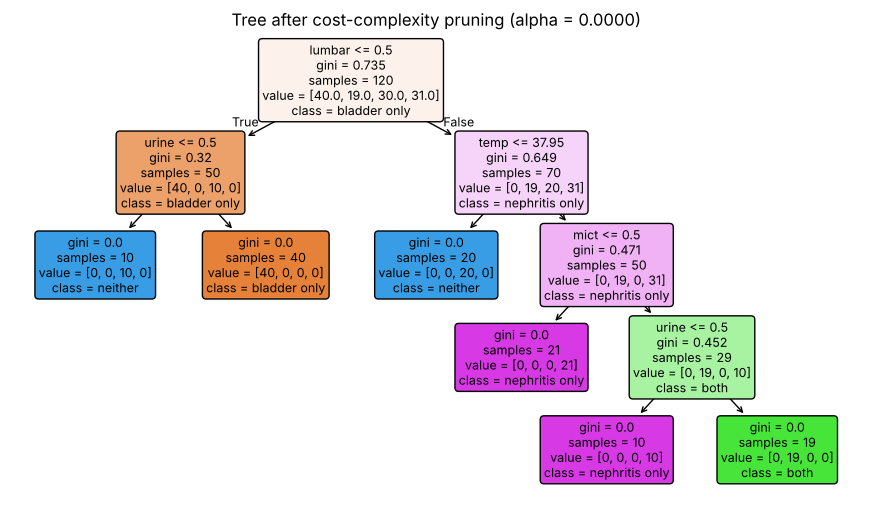

In [8]:
tp = DecisionTreeClassifier(random_state=552, ccp_alpha=ab).fit(X1, y1)
print(f"Pruned tree: {tp.get_n_leaves()} leaves, depth {tp.get_depth()}, training accuracy {tp.score(X1, y1):.3f}")
print("\n".join(rules(tp, list(X1.columns), tp.classes_)))
a2 = pt.alpha.iloc[1]
t2 = DecisionTreeClassifier(random_state=552, ccp_alpha=a2).fit(X1, y1)
print(f"\nNext pruning step (alpha = {a2:.4f}): {t2.get_n_leaves()} leaves, training accuracy {t2.score(X1, y1):.3f}")
print("\n".join(rules(t2, list(X1.columns), t2.classes_)))
plt.figure(figsize=(11, 6))
plot_tree(tp, feature_names=list(X1.columns), class_names=list(tp.classes_), filled=True, rounded=True, fontsize=9)
plt.title(f"Tree after cost-complexity pruning (alpha = {ab:.4f})")
plt.show()

After pruning, the alpha scores are:
alpha = 0.0000: 6 leaves, training accuracy 1.000, CV accuracy 0.992
alpha = 0.0982: 4 leaves, training accuracy 0.842, CV accuracy 0.858
alpha = 0.1333: 3 leaves, training accuracy 0.758, CV accuracy 0.767
alpha = 0.1820: 2 leaves, training accuracy 0.592, CV accuracy 0.675
alpha = 0.2229: 1 leaf, training accuracy 0.333, CV accuracy 0.483

I chose alpha by taking the largest alpha that reaches the best CV accuracy score. The best CV accuracy is 0.992 at alpha = 0, so the minimal accurate tree is the full 6-leaf tree, and its six rules in 1(c) are the interpretable rule set.

## 2(a)

In [9]:
cn = [l.split()[1] for l in open("../data/communities_crime/communities.names") if l.startswith("@attribute")]
cc = pd.read_csv("../data/communities_crime/communities.data", header=None, names=cn, na_values="?")
tr0, te0 = cc.iloc[:1495], cc.iloc[1495:]
print(cc.shape, tr0.shape, te0.shape)
cc.iloc[:5, :10]

(1994, 128) (1495, 128) (499, 128)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09


## 2(b)

In [10]:
cc = cc.drop(columns=cn[:5])
miss = cc.isna().sum()
print(miss[miss > 0].sort_values(ascending=False).to_string())
tg = "ViolentCrimesPerPop"
imp = SimpleImputer(strategy="median").fit(cc.iloc[:1495])
tr = pd.DataFrame(imp.transform(cc.iloc[:1495]), columns=cc.columns)
te = pd.DataFrame(imp.transform(cc.iloc[1495:]), columns=cc.columns)
Xtr, ytr, Xte, yte = tr.drop(columns=tg), tr[tg], te.drop(columns=tg), te[tg]
print(f"\nFeatures: {Xtr.shape[1]}, missing after imputation: {int(tr.isna().sum().sum() + te.isna().sum().sum())}")

LemasSwornFT            1675
LemasSwFTPerPop         1675
LemasSwFTFieldOps       1675
LemasTotalReq           1675
LemasSwFTFieldPerPop    1675
LemasTotReqPerPop       1675
PolicReqPerOffic        1675
OfficAssgnDrugUnits     1675
PolicPerPop             1675
RacialMatchCommPol      1675
PctPolicWhite           1675
PctPolicBlack           1675
PctPolicHisp            1675
PctPolicAsian           1675
PctPolicMinor           1675
PolicOperBudg           1675
NumKindsDrugsSeiz       1675
PolicAveOTWorked        1675
PolicCars               1675
LemasGangUnitDeploy     1675
LemasPctPolicOnPatr     1675
PolicBudgPerPop         1675
OtherPerCap                1

Features: 122, missing after imputation: 0


## 2(c)

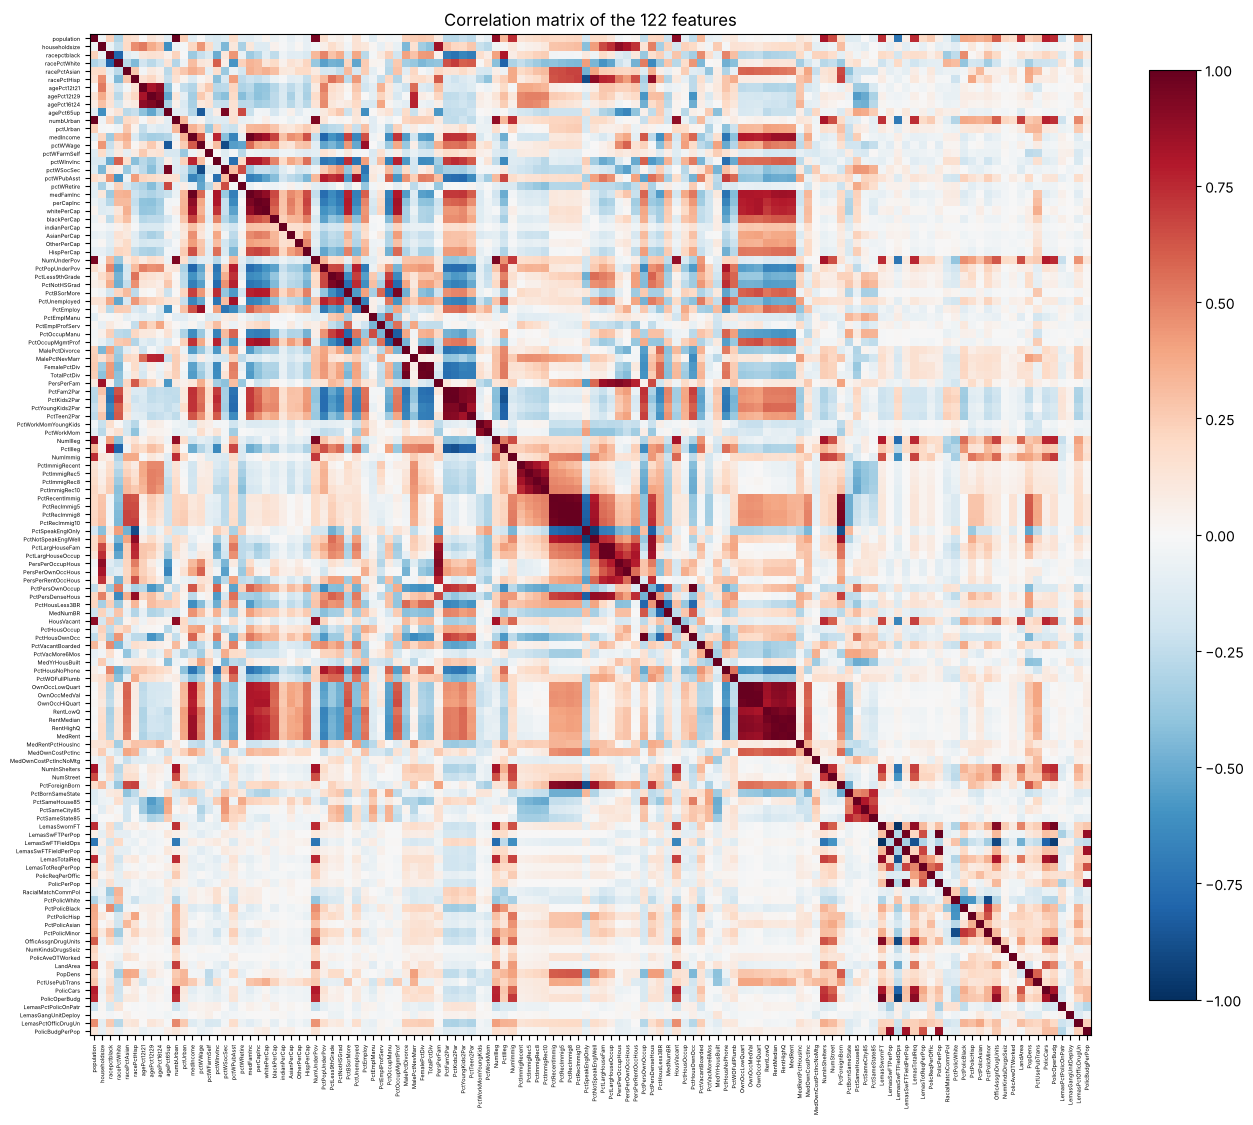

Pairs with |r| > 0.9: 58 of 7381
LemasSwFTPerPop  PolicPerPop      1.000
PctRecImmig8     PctRecImmig10    0.996
OwnOccLowQuart   OwnOccMedVal     0.994
PctRecImmig5     PctRecImmig8     0.993
population       numbUrban        0.993


In [11]:
full = pd.concat([tr, te], ignore_index=True)
cm = full.drop(columns=tg).corr()
fig, ax = plt.subplots(figsize=(15, 13))
im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cm)))
ax.set_yticks(range(len(cm)))
ax.set_xticklabels(cm.columns, rotation=90, fontsize=4)
ax.set_yticklabels(cm.columns, fontsize=4)
fig.colorbar(im, fraction=0.04)
ax.set_title("Correlation matrix of the 122 features")
plt.show()
u = cm.where(np.triu(np.ones(cm.shape, dtype=bool), 1)).stack().dropna()
print(f"Pairs with |r| > 0.9: {(u.abs() > 0.9).sum()} of {len(u)}")
print(u.abs().sort_values(ascending=False).head(5).round(3).to_string())

## 2(d)

In [12]:
cvf = (full.drop(columns=tg).std() / full.drop(columns=tg).mean()).sort_values(ascending=False)
print(cvf.round(4).to_string())

PctPolicAsian            5.4478
NumStreet                4.4077
NumInShelters            3.4855
NumIlleg                 2.9942
NumImmig                 2.9005
LemasPctOfficDrugUn      2.5553
NumUnderPov              2.3050
population               2.2035
LemasSwornFT             2.0807
numbUrban                2.0017
HousVacant               1.9588
LandArea                 1.6780
racePctHisp              1.6143
PolicOperBudg            1.5629
PctNotSpeakEnglWell      1.4591
PctUsePubTrans           1.4167
racepctblack             1.4109
LemasTotalReq            1.3817
racePctAsian             1.3592
PctPolicHisp             1.3263
PctRecentImmig           1.3001
PctRecImmig5             1.2976
PctRecImmig10            1.2840
PctRecImmig8             1.2812
PctPersDenseHous         1.1272
OfficAssgnDrugUnits      1.0886
PolicCars                1.0876
PctForeignBorn           1.0723
PctVacantBoarded         1.0647
PctIlleg                 0.9198
PctHousNoPhone           0.9182
OwnOccMe

## 2(e)

11 ['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'LemasSwornFT', 'numbUrban', 'HousVacant']


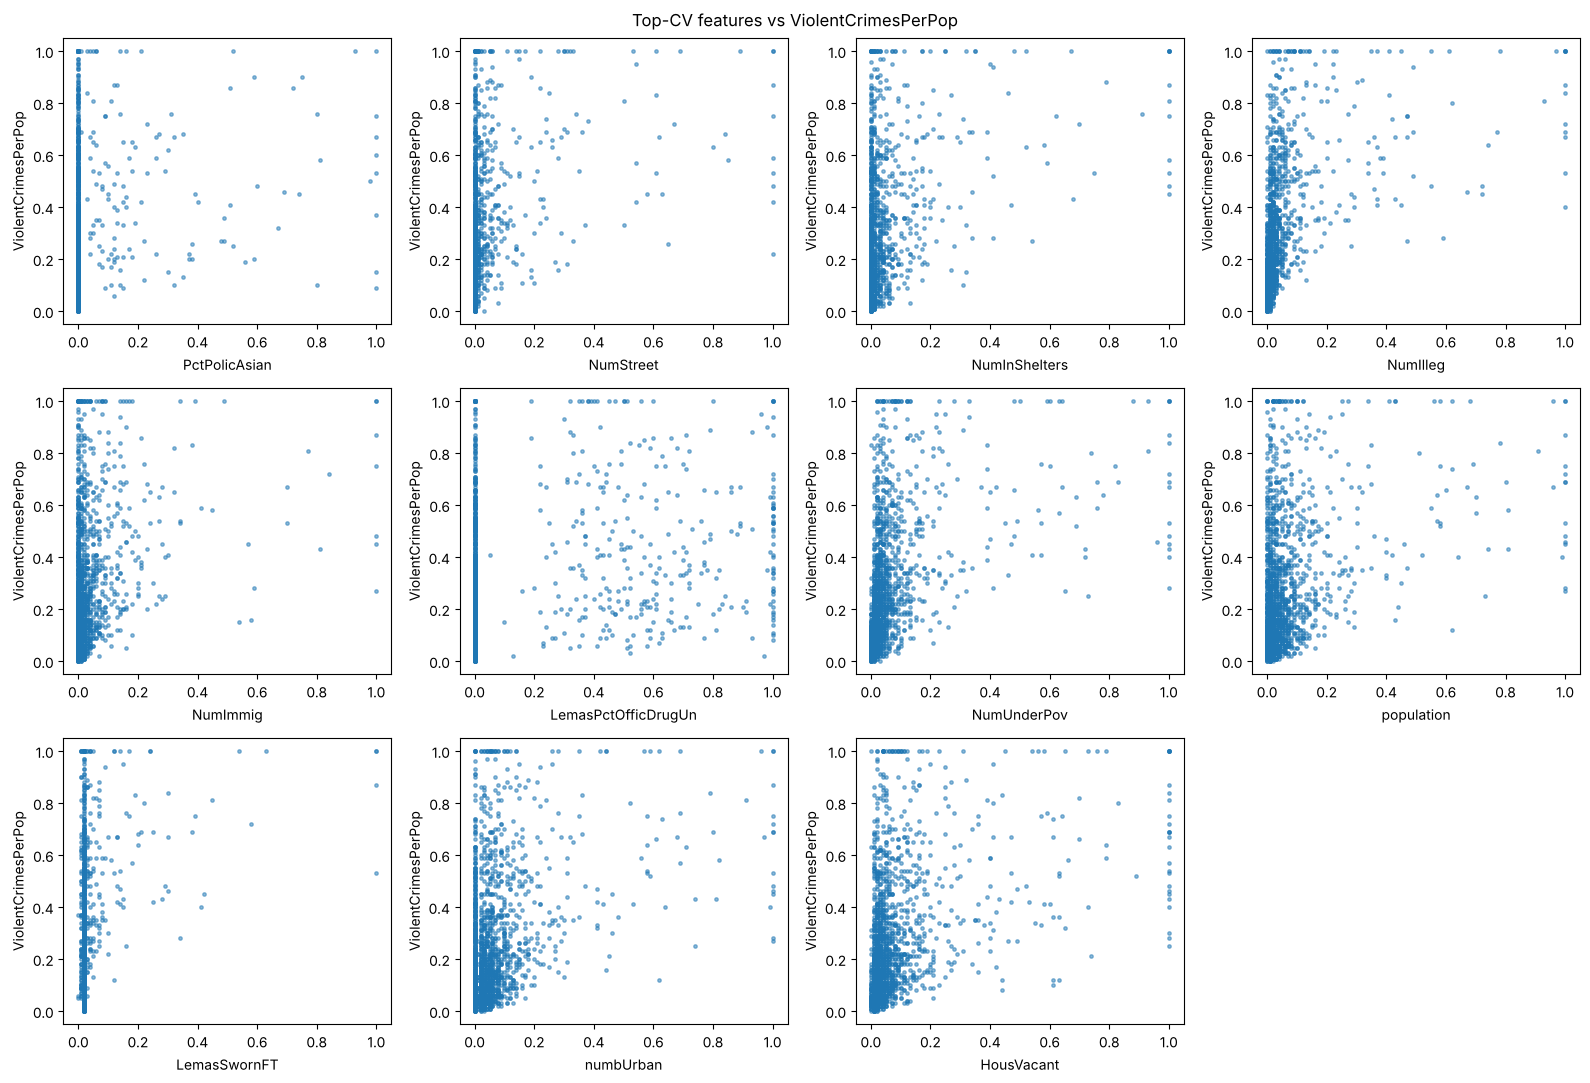

In [13]:
k = int(np.floor(np.sqrt(128)))
top = list(cvf.index[:k])
print(k, top)
fig, ax = plt.subplots(3, 4, figsize=(16, 11))
for a, f in zip(ax.ravel(), top):
    a.scatter(full[f], full[tg], s=6, alpha=0.5)
    a.set_xlabel(f)
    a.set_ylabel(tg)
ax.ravel()[-1].axis("off")
fig.suptitle("Top-CV features vs ViolentCrimesPerPop")
plt.tight_layout()
plt.show()

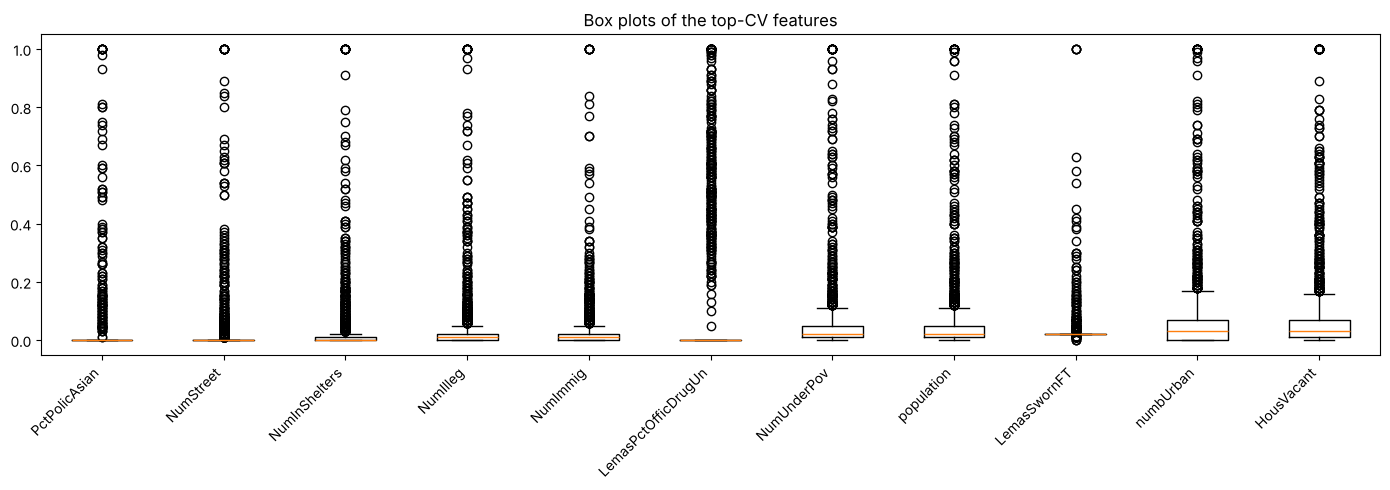

In [14]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.boxplot([full[f] for f in top])
ax.set_xticklabels(top, rotation=45, ha="right")
ax.set_title("Box plots of the top-CV features")
plt.tight_layout()
plt.show()

floor(sqrt(128)) = 11, so the top features are PctPolicAsian, NumStreet, NumInShelters, NumIlleg, NumImmig, LemasPctOfficDrugUn, NumUnderPov, population, LemasSwornFT, numbUrban and HousVacant.

In the scatter plots, most points pile up near 0 on the x axis, with a long tail of a few large communities. At x near 0, ViolentCrimesPerPop covers its whole 0-1 range. NumIlleg, NumUnderPov and HousVacant show a weak upward drift. So no, the scatter plots can't tell us whether these features are significant. Because of heavy skew, overlapping points and strongly correlated predictors, a visible trend could be hidden in the data in a full model.

## 2(f)

In [15]:
err = {}
ols = LinearRegression().fit(Xtr, ytr)
err["OLS"] = mean_squared_error(yte, ols.predict(Xte))
print(f"OLS test MSE: {err['OLS']:.5f}")
print(f"Baseline (training mean) test MSE: {mean_squared_error(yte, np.full(len(yte), ytr.mean())):.5f}")

OLS test MSE: 0.01797
Baseline (training mean) test MSE: 0.04767


Least squares on all 122 features gives a test MSE of 0.01797. For scale, predicting the training mean for every test community gives 0.04767, so least squares explains about 62% of the test variance.

## 2(g)

In [16]:
kf = KFold(10, shuffle=True, random_state=552)
rg = RidgeCV(alphas=np.logspace(-4, 4, 100), cv=kf).fit(Xtr, ytr)
err["Ridge"] = mean_squared_error(yte, rg.predict(Xte))
print(f"lambda = {rg.alpha_:.4f}, test MSE: {err['Ridge']:.5f}")

lambda = 2.7826, test MSE: 0.01749


Ridge gives a test MSE of 0.01749, lower than least squares (0.01797). Shrinking the coefficients reduces the variance caused by the strongly correlated features.

## 2(h)

In [17]:
ls = LassoCV(cv=kf, random_state=552, max_iter=50000).fit(Xtr, ytr)
err["LASSO"] = mean_squared_error(yte, ls.predict(Xte))
sel = list(Xtr.columns[ls.coef_ != 0])
print(f"lambda = {ls.alpha_:.6f}, test MSE: {err['LASSO']:.5f}, selected: {len(sel)} of {Xtr.shape[1]}")
print(", ".join(sel))
print(pd.Series(ls.coef_, Xtr.columns).abs().sort_values(ascending=False).head(5).round(4).to_string())

lambda = 0.000082, test MSE: 0.01769, selected: 79 of 122
racepctblack, racePctAsian, agePct12t21, agePct12t29, agePct65up, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, medFamInc, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctBSorMore, PctEmploy, PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMomYoungKids, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRec10, PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PersPerOwnOccHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctSameCity85, LemasSwFTFieldPerPop, LemasTotalReq, Po

In [18]:
sc = StandardScaler().fit(Xtr)
lz = LassoCV(cv=kf, random_state=552, max_iter=50000).fit(sc.transform(Xtr), ytr)
err["LASSO std"] = mean_squared_error(yte, lz.predict(sc.transform(Xte)))
sz = list(Xtr.columns[lz.coef_ != 0])
print(f"lambda = {lz.alpha_:.6f}, test MSE: {err['LASSO std']:.5f}, selected: {len(sz)} of {Xtr.shape[1]}")
print(", ".join(sz))
print(f"\nSelected by both: {len(set(sel) & set(sz))}, raw only: {len(set(sel) - set(sz))}, standardized only: {len(set(sz) - set(sel))}")

lambda = 0.000619, test MSE: 0.01773, selected: 76 of 122
racepctblack, racePctAsian, agePct12t21, agePct12t29, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctEmploy, PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRecent, PctImmigRec10, PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PersPerOwnOccHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctSameCity85, LemasSwFTFieldPerPop, LemasTotalReq, PolicReqPerOffic, RacialMatchCommPol, PctPo

With the original 0-1 features, 10-fold CV picks lambda = 0.000082. Test MSE is 0.01769, with 79 of 122 features kept. The largest coefficients are agePct12t29 (0.320), racepctblack (0.270), PctPersDenseHous (0.238), and PctKids2Par (0.201).

With standardized features, CV picks lambda = 0.000619. Test MSE is 0.01773, with 76 features kept. The two models share 75 features. Only the unstandardized model keeps agePct65up, medFamInc, PctBSorMore, and PctWorkMomYoungKids. Only the standardized one keeps PctImmigRecent.

The test errors are nearly identical; since the features are already on a 0-1 scale, standardizing just rescales each one, which shifts lambda and a few borderline features but not the overall fit. Both LASSO models beat least squares slightly and trail ridge.

## 2(i)

M = 97, CV MSE = 0.01949, test MSE: 0.01837


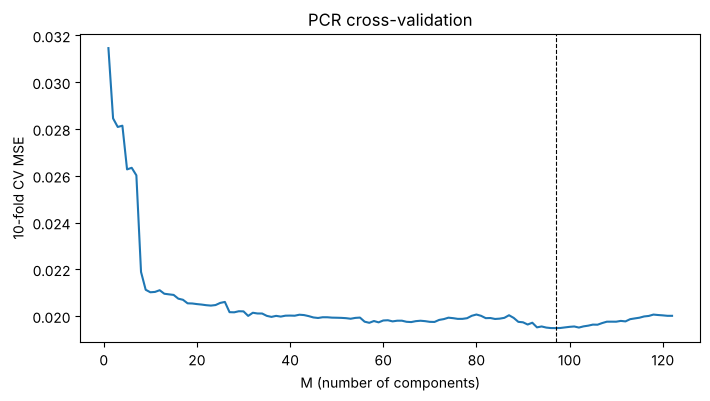

In [19]:
pm = [-cross_val_score(make_pipeline(StandardScaler(), PCA(m), LinearRegression()), Xtr, ytr, cv=kf, scoring="neg_mean_squared_error").mean() for m in range(1, Xtr.shape[1] + 1)]
M = int(np.argmin(pm)) + 1
pcr = make_pipeline(StandardScaler(), PCA(M), LinearRegression()).fit(Xtr, ytr)
err["PCR"] = mean_squared_error(yte, pcr.predict(Xte))
print(f"M = {M}, CV MSE = {min(pm):.5f}, test MSE: {err['PCR']:.5f}")
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(pm) + 1), pm)
plt.axvline(M, color="k", ls="--", lw=0.8)
plt.xlabel("M (number of components)")
plt.ylabel("10-fold CV MSE")
plt.title("PCR cross-validation")
plt.show()

The CV curve drops sharply over the first 10 components and is nearly flat from about 30 to 110, so many values of M perform about the same. PCR does slightly worse than least squares here because it picks components by how much feature variance they capture, not by how well they predict crime.

## 2(j)

In [20]:
gs = GridSearchCV(XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=552, n_jobs=4),
                  {"reg_alpha": [0, 0.001, 0.01, 0.1, 0.5, 1, 2, 5, 10]}, cv=kf, scoring="neg_mean_squared_error").fit(Xtr, ytr)
err["XGBoost L1"] = mean_squared_error(yte, gs.predict(Xte))
print(pd.DataFrame({"alpha": gs.cv_results_["param_reg_alpha"], "cv_mse": -gs.cv_results_["mean_test_score"]}).round(5).to_string(index=False))
print(f"\nalpha = {gs.best_params_['reg_alpha']}, test MSE: {err['XGBoost L1']:.5f}")

 alpha  cv_mse
 0.000 0.01955
 0.001 0.01955
 0.010 0.01946
 0.100 0.01967
 0.500 0.01918
 1.000 0.01917
 2.000 0.01908
 5.000 0.01998
10.000 0.02087

alpha = 2, test MSE: 0.01614


In [21]:
print(pd.Series(err, name="test MSE").round(5).to_string())

OLS           0.01797
Ridge         0.01749
LASSO         0.01769
LASSO std     0.01773
PCR           0.01837
XGBoost L1    0.01614


Using XGBoost with 300 trees of depth 3 and a learning rate of 0.05, 10-fold CV over alpha from 0 to 10 picks alpha = 2, with a CV MSE of 0.01908 and the boosted model's test MSE is 0.01614.